In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
df=pd.read_csv("spam.csv",encoding="latin-1")
print(df.shape)
df.head()

(5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB
None


In [ ]:
print(df["v1"].value_counts())
df.sample(3)

v1
ham     4825
spam     747
Name: count, dtype: int64


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
5087,ham,"Good morning, im suffering from fever and dyse...",NaN,NaN,NaN
5024,ham,I was gonna ask you lol but i think its at 7,NaN,NaN,NaN
5166,ham,Y she dun believe leh? I tot i told her it's t...,NaN,NaN,NaN


Data Cleaning

In [ ]:
#dropping irrelevant columns (last 2)
df=df[["v1","v2"]]
df

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [ ]:
#rename columns
df.rename(columns={"v1":"target","v2":'text'},inplace=True)
df.sample(5)

,target,text
2588,ham,My superior telling that friday is leave for a...
2813,ham,"Alright if you're sure, let me know when you'r..."
4241,spam,Show ur colours! Euro 2004 2-4-1 Offer! Get an...
2547,spam,"Text82228>> Get more ringtones, logos and game..."
1715,ham,Asking do u knw them or nt? May be ur frnds or...


In [ ]:
#encoding the output feature
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()
df["target"]=encoder.fit_transform(df["target"])
df.sample(5)

,target,text
2261,0,Did you show him and wot did he say or could u...
1136,1,Dont forget you can place as many FREE Request...
2548,0,Honestly i've just made a lovely cup of tea an...
1013,0,Just buy a pizza. Meat lovers or supreme. U ge...
1530,0,I think chennai well settled?


In [ ]:
#missing Values
print(df.isna().sum())

target    0
text      0
dtype: int64


In [ ]:
#duplicate values
print(df.duplicated().sum())
df=df.drop_duplicates(keep="first")
print(df.duplicated().sum())

403
0


EDA

target
0    4516
1     653
Name: count, dtype: int64


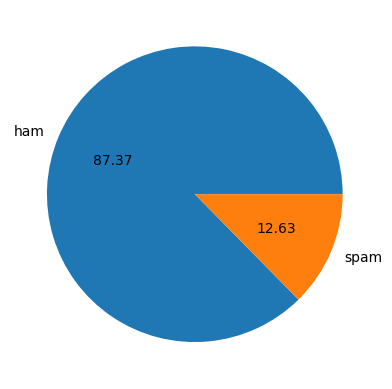

In [ ]:
print(df["target"].value_counts())
import matplotlib.pyplot as plt
plt.pie(df["target"].value_counts(),labels=["ham","spam"],autopct="%0.2f")
plt.show()

In [ ]:
import nltk
nltk.download("punkt")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [ ]:
#number of characters
df["num_chars"]=df["text"].apply(len)

/tmp/ipykernel_1476/1199160551.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["num_chars"]=df["text"].apply(len)


In [ ]:
#number of words
nltk.download("punkt_tab")
df["num_words"]=df["text"].apply(lambda x:len(nltk.word_tokenize(x)))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
/tmp/ipykernel_1476/277338392.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["num_words"]=df["text"].apply(lambda x:len(nltk.word_tokenize(x)))


In [ ]:
#number of sentences
df["num_sentences"]=df["text"].apply(lambda x:len(nltk.sent_tokenize(x)))

/tmp/ipykernel_1476/3525242329.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["num_sentences"]=df["text"].apply(lambda x:len(nltk.sent_tokenize(x)))


In [ ]:
df.head()

,target,text,num_chars,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [ ]:
df.describe()

,target,num_chars,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000,5169.000000
mean,0.126330,78.977945,18.455794,1.965564
std,0.332253,58.236293,13.324758,1.448541
min,0.000000,2.000000,1.000000,1.000000
25%,0.000000,36.000000,9.000000,1.000000
50%,0.000000,60.000000,15.000000,1.000000
75%,0.000000,117.000000,26.000000,2.000000
max,1.000000,910.000000,220.000000,38.000000


In [ ]:
df[df["target"]==0][["num_words","num_chars","num_sentences"]].describe()

,num_words,num_chars,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,17.123782,70.459256,1.820195
std,13.493970,56.358207,1.383657
min,1.000000,2.000000,1.000000
25%,8.000000,34.000000,1.000000
50%,13.000000,52.000000,1.000000
75%,22.000000,90.000000,2.000000
max,220.000000,910.000000,38.000000


<Axes: xlabel='num_chars', ylabel='Count'>

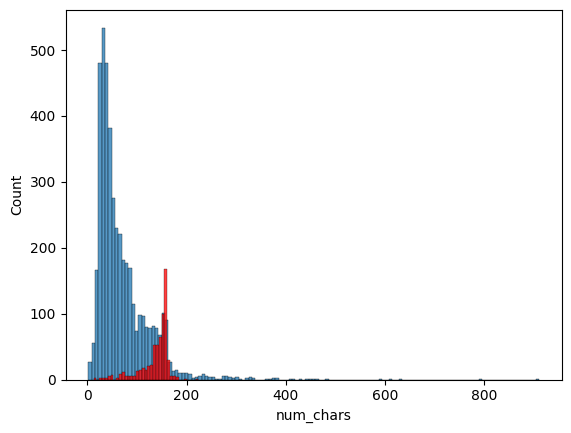

In [ ]:
import seaborn as sns
sns.histplot(df[df["target"]==0]["num_chars"])
sns.histplot(df[df["target"]==1]["num_chars"],color="red")

<Axes: xlabel='num_words', ylabel='Count'>

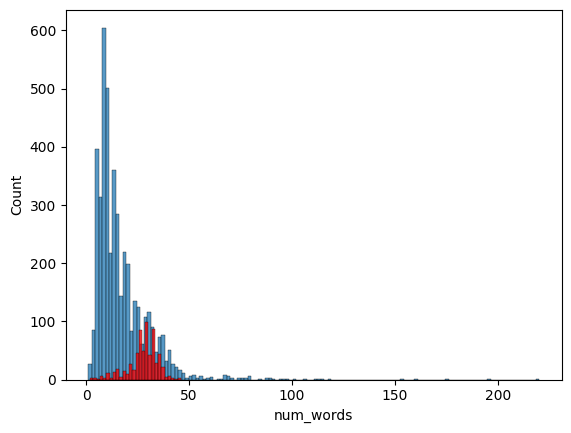

In [ ]:
sns.histplot(df[df["target"]==0]["num_words"])
sns.histplot(df[df["target"]==1]["num_words"],color="red")

<Axes: xlabel='num_sentences', ylabel='Count'>

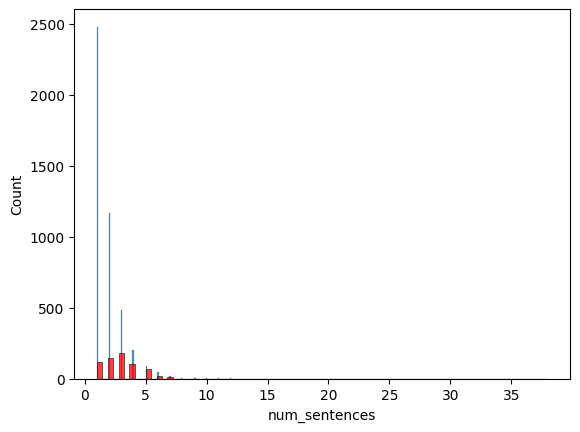

In [ ]:
sns.histplot(df[df["target"]==0]["num_sentences"])
sns.histplot(df[df["target"]==1]["num_sentences"],color="red")

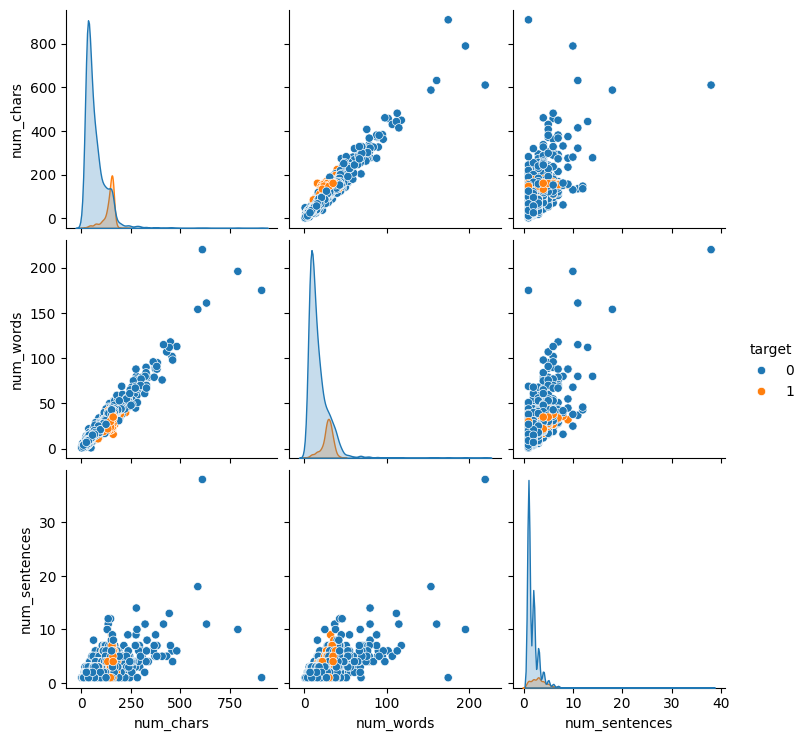

In [ ]:
sns.pairplot(df,hue="target")

<Axes: >

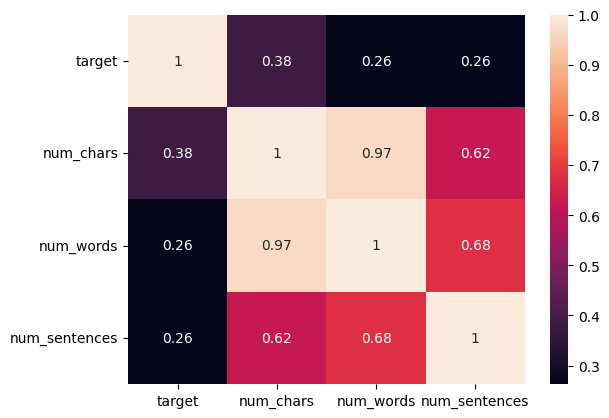

In [ ]:
sns.heatmap(df.select_dtypes(include="number").corr(),annot=True)

In [ ]:
#num of words, no of characters and number of sentences are very highly correlated hence keep only one of them
df=df[["target","text","num_chars"]]

Data Preprocessing

In [ ]:
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords
stopwords.words("english")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [ ]:
from nltk.stem.porter import PorterStemmer
ps=PorterStemmer()
print(ps.stem("Dancing"))

danc


In [ ]:
import string
def transform_text(text):
  text=text.lower()
  text=nltk.word_tokenize(text)
  y=[]
  for i in text:
    if i.isalnum():
      y.append(i)
  text=y.copy()
  y.clear()
  for i in text:
    if i not in stopwords.words("english") and i not in string.punctuation:
      y.append(i)
  text=y.copy()
  y.clear()
  for i in text:
    y.append(ps.stem(i))

  return " ".join(y)

In [ ]:
import string
s="I loved the youtube lectures on ML, how about you?"
print(transform_text(s))

love youtub lectur ml


In [ ]:
df["transformed_text"]=df["text"].apply(transform_text)
df.head()

/tmp/ipykernel_1476/3651123226.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["transformed_text"]=df["text"].apply(transform_text)


,target,text,num_chars,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,nah think goe usf live around though


In [ ]:
from wordcloud import WordCloud
wc=WordCloud(width=50,height=50,min_font_size=10,background_color="white")

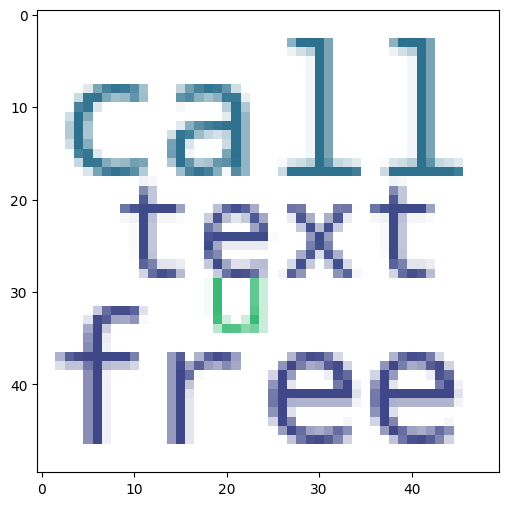

In [ ]:
spam_wc=wc.generate(df[df["target"]==1]["transformed_text"].str.cat(sep=" "))
plt.figure(figsize=(12,6))
plt.imshow(spam_wc)

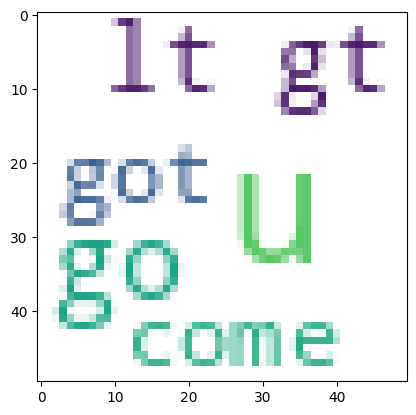

In [ ]:
ham_wc=wc.generate(df[df["target"]==0]["transformed_text"].str.cat(sep=" "))
plt.imshow(ham_wc)

In [ ]:
df.head()

,target,text,num_chars,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,nah think goe usf live around though


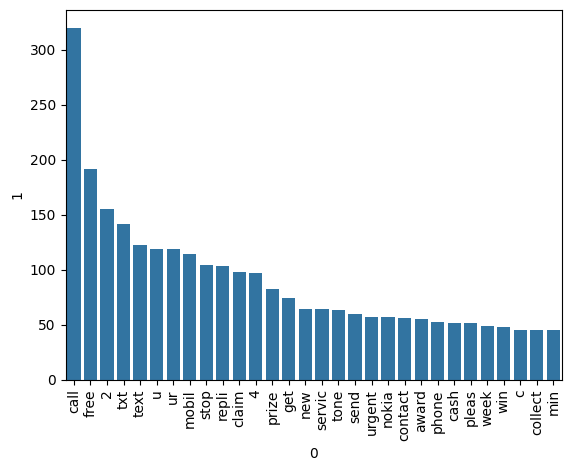

In [ ]:
spam_corpus=[]
for i in df[df["target"]==1]["transformed_text"].tolist():
  for word in i.split():
    spam_corpus.append(word)
from collections import Counter
spam_df=pd.DataFrame(Counter(spam_corpus).most_common(30))
sns.barplot(x=spam_df[0],y=spam_df[1])
plt.xticks(rotation="vertical")
plt.show()

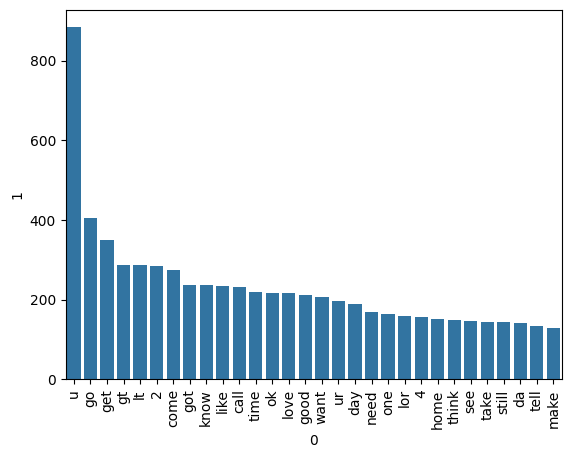

In [ ]:
ham_corpus=[]
for i in df[df["target"]==0]["transformed_text"].tolist():
  for word in i.split():
    ham_corpus.append(word)
from collections import Counter
ham_df=pd.DataFrame(Counter(ham_corpus).most_common(30))
sns.barplot(x=ham_df[0],y=ham_df[1])
plt.xticks(rotation="vertical")
plt.show()

Model Building

In [ ]:
#naive bayes model

#step1-Vectorization
from sklearn.feature_extraction.text import CountVectorizer
cv=CountVectorizer()
X=cv.fit_transform(df["transformed_text"]).toarray()
print(X.shape)

(5169, 6708)


In [ ]:
y=df["target"].values
y

array([0, 0, 1, ..., 0, 0, 0])

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y)


In [ ]:
from sklearn.naive_bayes import GaussianNB,BernoulliNB,MultinomialNB
gnb=GaussianNB()
bnb=BernoulliNB()
mnb=MultinomialNB()

Gaussian Naive Bayes

In [ ]:
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score
gnb.fit(X_train,y_train)
y_pred1=gnb.predict(X_test)
print(accuracy_score(y_test,y_pred1))
print(confusion_matrix(y_test,y_pred1))
print(precision_score(y_test,y_pred1))


0.8654292343387471
[[969 151]
 [ 23 150]]
0.4983388704318937


Bernoulli Naive Bayes

In [ ]:
bnb.fit(X_train,y_train)
y_pred2=bnb.predict(X_test)
print(accuracy_score(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred2))
print(precision_score(y_test,y_pred2))

0.9651972157772621
[[1114    6]
 [  39  134]]
0.9571428571428572


Multinomial Naive Bayes

In [ ]:
mnb.fit(X_train,y_train)
y_pred3=mnb.predict(X_test)
print(accuracy_score(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))
print(precision_score(y_test,y_pred3))

0.9737045630317092
[[1100   20]
 [  14  159]]
0.888268156424581


Using tfidf

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer()
tfidf3000=TfidfVectorizer(max_features=3000)
X3000=tfidf3000.fit_transform(df["transformed_text"]).toarray()
X=tfidf.fit_transform(df["transformed_text"]).toarray()
y=df["target"].values

X_train,X_test,y_train,y_test=train_test_split(X,y)
X_train3000,X_test3000,y_train3000,y_test3000=train_test_split(X3000,y)

In [ ]:
gnb.fit(X_train,y_train)
y_pred1=gnb.predict(X_test)
print(accuracy_score(y_test,y_pred1))
print(confusion_matrix(y_test,y_pred1))
print(precision_score(y_test,y_pred1))

0.8662026295436969
[[978 152]
 [ 21 142]]
0.48299319727891155


In [ ]:
bnb.fit(X_train,y_train)
y_pred2=bnb.predict(X_test)
print(accuracy_score(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred2))
print(precision_score(y_test,y_pred2))

0.9737045630317092
[[1126    4]
 [  30  133]]
0.9708029197080292


In [ ]:
mnb.fit(X_train,y_train)
y_pred3=mnb.predict(X_test)
print(accuracy_score(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))
print(precision_score(y_test,y_pred3))

0.9582366589327146
[[1130    0]
 [  54  109]]
1.0


Best Model Yet:  **tfidf + mnb**



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

In [ ]:
svc = SVC(kernel='sigmoid', gamma=1.0)
knc = KNeighborsClassifier()
mnb = MultinomialNB()
dtc = DecisionTreeClassifier(max_depth=5)
lrc = LogisticRegression(solver='liblinear', penalty='l1')
rfc = RandomForestClassifier(n_estimators=50, random_state=2)
abc = AdaBoostClassifier(n_estimators=50, random_state=2)
bc = BaggingClassifier(n_estimators=50, random_state=2)
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)
gbdt = GradientBoostingClassifier(n_estimators=50,random_state=2)
xgb = XGBClassifier(n_estimators=50,random_state=2)

In [ ]:
clfs = {
    'SVC' : svc,
    'KN' : knc,
    'NB': mnb,
    'DT': dtc,
    'LR': lrc,
    'RF': rfc,
    'AdaBoost': abc,
    'BgC': bc,
    'ETC': etc,
    'GBDT':gbdt,
    'xgb':xgb
}

In [ ]:
def train_classifier(clf,X_train,y_train,X_test,y_test):
    clf.fit(X_train,y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test,y_pred)
    precision = precision_score(y_test,y_pred)

    return accuracy,precision

In [ ]:
train_classifier(svc,X_train,y_train,X_test,y_test)

(0.9783449342614076, 0.9787234042553191)

In [ ]:
accuracy_scores = []
precision_scores = []

for name,clf in clfs.items():

    current_accuracy,current_precision = train_classifier(clf, X_train,y_train,X_test,y_test)

    print("For ",name)
    print("Accuracy - ",current_accuracy)
    print("Precision - ",current_precision)

    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)

For  SVC
Accuracy -  0.9783449342614076
Precision -  0.9787234042553191
For  KN
Accuracy -  0.8994586233565351
Precision -  1.0
For  NB
Accuracy -  0.9582366589327146
Precision -  1.0
For  DT
Accuracy -  0.945862335653519
Precision -  0.8661417322834646
For  LR
Accuracy -  0.9582366589327146
Precision -  0.957983193277311
For  RF
Accuracy -  0.9706109822119103
Precision -  0.9921259842519685
For  AdaBoost
Accuracy -  0.9319412219644239
Precision -  0.8260869565217391
For  BgC
Accuracy -  0.9675174013921114
Precision -  0.8954248366013072
For  ETC
Accuracy -  0.9737045630317092
Precision -  0.9849624060150376
For  GBDT
Accuracy -  0.9559164733178654
Precision -  0.9344262295081968
For  xgb
Accuracy -  0.9737045630317092
Precision -  0.9448275862068966


In [ ]:
performance_df = pd.DataFrame({'Algorithm':clfs.keys(),'Accuracy':accuracy_scores,'Precision':precision_scores}).sort_values('Precision',ascending=False)

In [ ]:
performance_df

,Algorithm,Accuracy,Precision
1,KN,0.899459,1.000000
2,NB,0.958237,1.000000
5,RF,0.970611,0.992126
8,ETC,0.973705,0.984962
0,SVC,0.978345,0.978723
4,LR,0.958237,0.957983
10,xgb,0.973705,0.944828
9,GBDT,0.955916,0.934426
7,BgC,0.967517,0.895425
3,DT,0.945862,0.866142


In [ ]:
performance_df1=pd.melt(performance_df,id_vars="Algorithm")
performance_df1

,Algorithm,variable,value
0,KN,Accuracy,0.899459
1,NB,Accuracy,0.958237
2,RF,Accuracy,0.970611
3,ETC,Accuracy,0.973705
4,SVC,Accuracy,0.978345
5,LR,Accuracy,0.958237
6,xgb,Accuracy,0.973705
7,GBDT,Accuracy,0.955916
8,BgC,Accuracy,0.967517
9,DT,Accuracy,0.945862


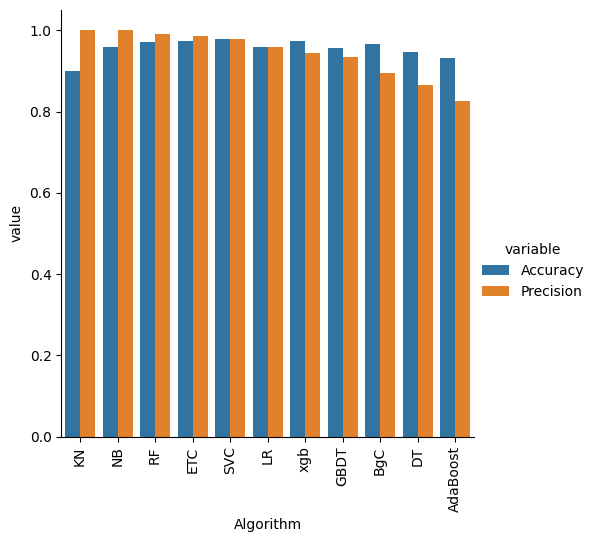

In [ ]:
sns.catplot(x="Algorithm",y="value",hue="variable",data=performance_df1,kind="bar")
plt.xticks(rotation="vertical")
plt.show()

improve model

In [ ]:
accuracy_scores=[]
precision_scores=[]

In [ ]:
# 1.change the max_features for tfidf
for name,clf in clfs.items():

    current_accuracy,current_precision = train_classifier(clf, X_train3000,y_train3000,X_test3000,y_test3000)

    print("For ",name)
    print("Accuracy - ",current_accuracy)
    print("Precision - ",current_precision)

    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)

For  SVC
Accuracy -  0.9822119102861562
Precision -  0.9784172661870504
For  KN
Accuracy -  0.9149265274555298
Precision -  1.0
For  NB
Accuracy -  0.9783449342614076
Precision -  0.9923076923076923
For  DT
Accuracy -  0.9450889404485692
Precision -  0.8899082568807339
For  LR
Accuracy -  0.9644238205723125
Precision -  0.9661016949152542
For  RF
Accuracy -  0.979891724671307
Precision -  1.0
For  AdaBoost
Accuracy -  0.9365815931941222
Precision -  0.8557692307692307
For  BgC
Accuracy -  0.9675174013921114
Precision -  0.875
For  ETC
Accuracy -  0.9822119102861562
Precision -  0.9784172661870504
For  GBDT
Accuracy -  0.9574632637277649
Precision -  0.963302752293578
For  xgb
Accuracy -  0.9706109822119103
Precision -  0.9538461538461539


In [ ]:
temp_df=pd.DataFrame({"Algorithm":clfs.keys(),"Accuracy_max_ft_3000":accuracy_scores,'Precision_max_ft_3000':precision_scores}).sort_values('Precision_max_ft_3000',ascending=False)

In [ ]:
performance_df=performance_df.merge(temp_df,on="Algorithm")

In [ ]:
performance_df

,Algorithm,Accuracy,Precision,Accuracy_max_ft_3000,Precision_max_ft_3000
0,KN,0.899459,1.000000,0.914927,1.000000
1,NB,0.958237,1.000000,0.978345,0.992308
2,RF,0.970611,0.992126,0.979892,1.000000
3,ETC,0.973705,0.984962,0.982212,0.978417
4,SVC,0.978345,0.978723,0.982212,0.978417
5,LR,0.958237,0.957983,0.964424,0.966102
6,xgb,0.973705,0.944828,0.970611,0.953846
7,GBDT,0.955916,0.934426,0.957463,0.963303
8,BgC,0.967517,0.895425,0.967517,0.875000
9,DT,0.945862,0.866142,0.945089,0.889908


In [ ]:
# Voting Classifier
svc = SVC(kernel='sigmoid', gamma=1.0,probability=True)
mnb = MultinomialNB()
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)

from sklearn.ensemble import VotingClassifier

In [ ]:
voting = VotingClassifier(estimators=[('svm', svc), ('nb', mnb), ('et', etc)],voting='soft')

In [ ]:
voting.fit(X_train,y_train)

VotingClassifier(estimators=[('svm',
                              SVC(gamma=1.0, kernel='sigmoid',
                                  probability=True)),
                             ('nb', MultinomialNB()),
                             ('et',
                              ExtraTreesClassifier(n_estimators=50,
                                                   random_state=2))],
                 voting='soft')

In [ ]:
y_pred = voting.predict(X_test)
print("Accuracy",accuracy_score(y_test,y_pred))
print("Precision",precision_score(y_test,y_pred))

Accuracy 0.982985305491106
Precision 1.0


In [ ]:
# Applying stacking
estimators=[('svm', svc), ('nb', mnb), ('et', etc)]
final_estimator=RandomForestClassifier()

In [ ]:
# from sklearn.ensemble import StackingClassifier
# clf = StackingClassifier(estimators=estimators, final_estimator=final_estimator)
# clf.fit(X_train,y_train)
# y_pred = clf.predict(X_test)
# print("Accuracy",accuracy_score(y_test,y_pred))
# print("Precision",precision_score(y_test,y_pred))

In [ ]:
import pickle
pickle.dump(tfidf,open('vectorizer.pkl','wb'))
pickle.dump(mnb,open('model.pkl','wb'))